# Logistic Regression: From Linear Models to Classification

Linear Regression works well for predicting continuous values like house prices or salaries. However, when predicting **discrete (binary) outcomes**—such as whether a transaction is fraudulent or legitimate, or whether a patient has a disease—Linear Regression breaks down.

Logistic Regression is designed specifically to solve classification problems by mapping any real-valued input to a **probability between 0 and 1**.

## 1. Why Linear Regression Fails for Classification

Linear regression predicts targets using a straight line:

$$
y = \boldsymbol{w}^T \boldsymbol{x} + b
$$

Attempting to use Linear Regression for a binary outcome ($y \in \{0, 1\}$) creates two major problems:

```
Unbounded Outputs in Linear Regression:

Probability
^
1.5 |                              /  <-- Output > 1 (Invalid probability!)
1.0 |----------------------------/--- Decision Boundary (y = 1)
0.5 |                          /
0.0 |------------------------/------- Decision Boundary (y = 0)
-0.5|                      /    <-- Output < 0 (Invalid probability!)
+----------------------------------> x

```

1. **Unbounded Predictions:** Predictions can be far outside the $[0, 1]$ range (e.g., $-0.5$ or $1.8$), making them impossible to interpret as probabilities.
2. **Sensitivity to Outliers:** A single extreme data point far to the right pulls the regression line down, shifting the decision threshold and misclassifying previously correct points.

## 2. The Sigmoid Function

To constrain the model output between $0$ and $1$, Logistic Regression applies the **Sigmoid (or Logistic) Function** $\sigma(z)$ to the linear combination $z = \boldsymbol{w}^T \boldsymbol{x} + b$:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

### Mathematical Properties

- **Output Range:** As $z \to \infty$, $\sigma(z) \to 1$. As $z \to -\infty$, $\sigma(z) \to 0$.
- **Symmetry:** $\sigma(-z) = 1 - \sigma(z)$.
- **Derivative:** $\frac{d\sigma}{dz} = \sigma(z)(1 - \sigma(z))$ *(crucial for gradient descent)*.

Here is a proper plot of the Sigmoid function $\sigma(z) = \frac{1}{1 + e^{-z}}$:

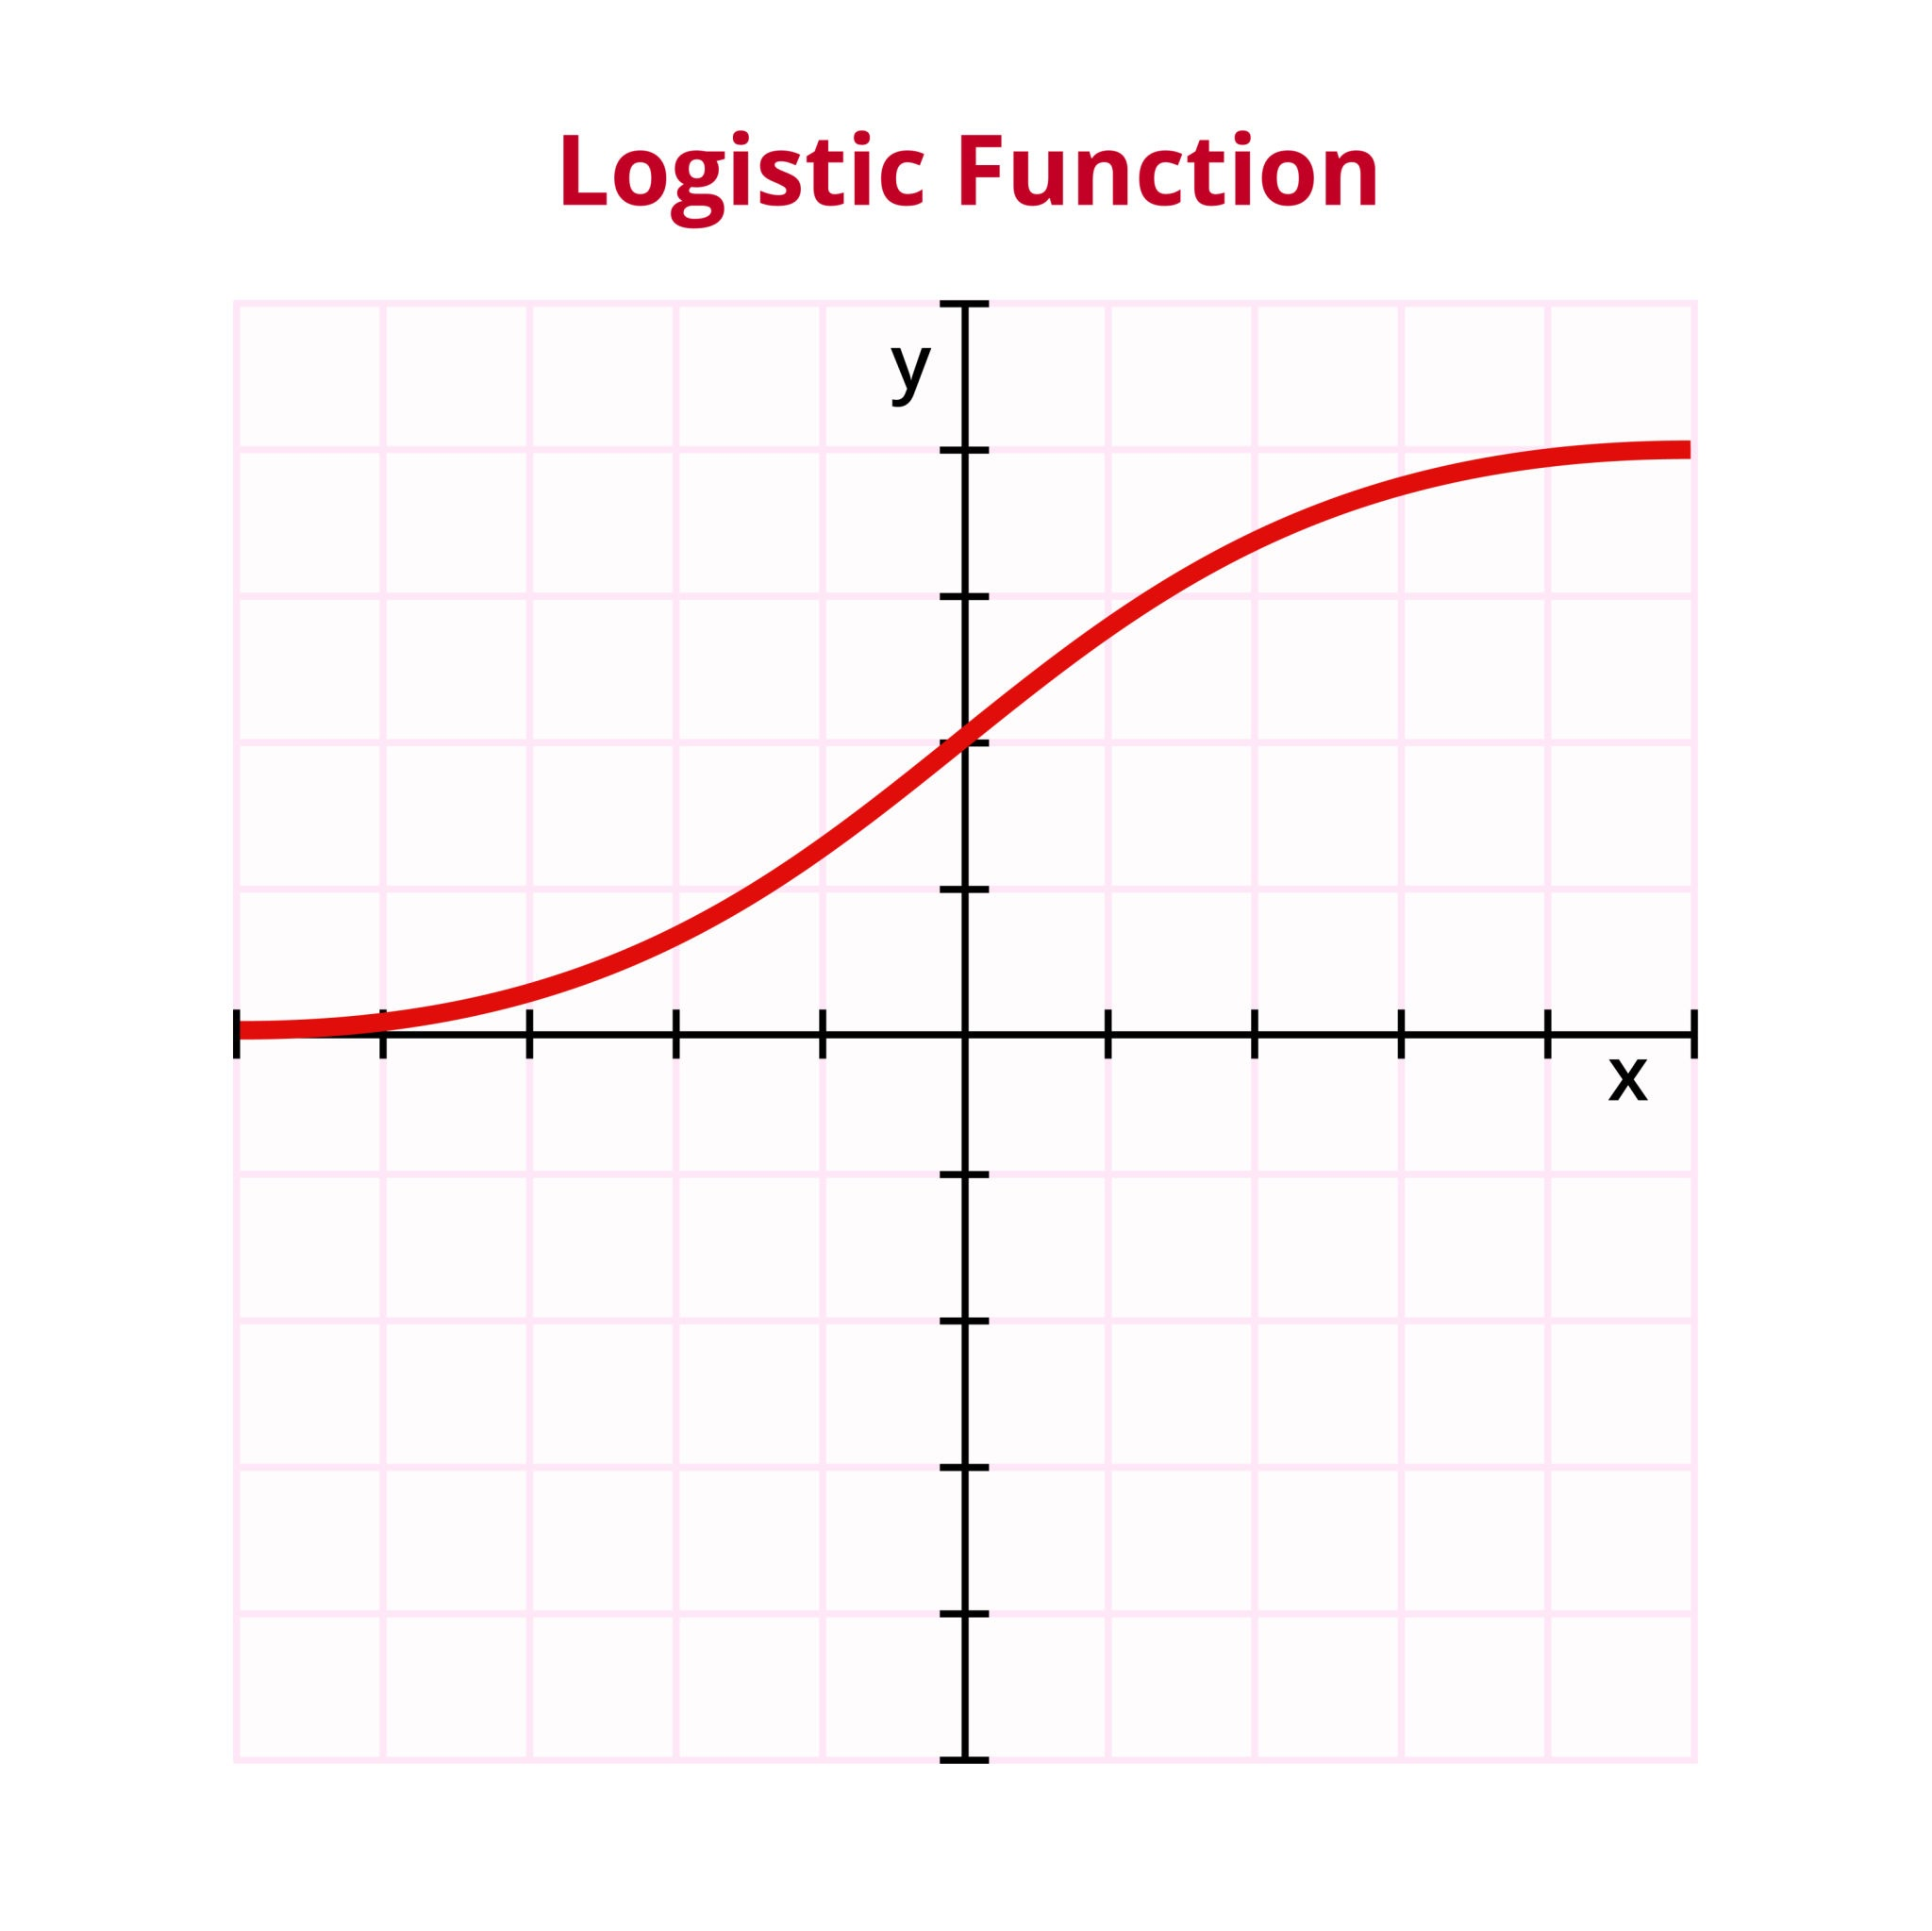

### Key Visual Takeaways to Notice:

1. **Symmetric Inflection Point:** At $z = 0$, the curve crosses exactly at $y = 0.5$.
2. **Horizontal Asymptotes:**
- As $z \to \infty$, the output approaches $1.0$ (never quite touching it).
- As $z \to -\infty$, the output approaches $0.0$ (never quite touching it).
3. **Maximum Slope at Center:** The curve is steepest at $z = 0$, where the derivative $\sigma'(0) = 0.5(1 - 0.5) = 0.25$ is at its maximum. Far to the left or right, the curve flattens completely—which is what causes the **vanishing gradient problem** when using MSE loss.

### Probability Interpretation

The output $\hat{y} = \sigma(z)$ represents the conditional probability of class 1:

$$
\hat{y} = P(y = 1 \mid \boldsymbol{x})
$$

$$
1 - \hat{y} = P(y = 0 \mid \boldsymbol{x})
$$

The default decision threshold is set at $0.5$:

$$
\text{Class} = \begin{cases} 1 & \text{if } \hat{y} \ge 0.5 \quad (z \ge 0) \\ 0 & \text{if } \hat{y} \lt 0.5 \quad (z \lt 0) \end{cases}
$$

## 3. The Loss Function: Binary Cross-Entropy

### Why Mean Squared Error (MSE) Fails

If we plug the non-linear Sigmoid output into the Mean Squared Error loss function $L_{MSE} = \frac{1}{2}(\sigma(z) - y)^2$:

$$
\frac{\partial L_{MSE}}{\partial w_j} = (\hat{y} - y) \cdot \underbrace{\sigma(z)(1 - \sigma(z))}_{\text{Sigmoid Derivative}} \cdot x_j
$$

When the model makes a **confident but wrong** prediction (e.g., $z = 10$, so $\hat{y} \approx 1.0$, but true $y = 0$):

- $\sigma(10)(1 - \sigma(10)) \approx 1 \cdot 0 = 0$
- The gradient vanishes ($\frac{\partial L_{MSE}}{\partial w_j} \approx 0$), leaving the model **stuck** without updating its weights despite a massive prediction error.
- Furthermore, MSE combined with Sigmoid creates a **non-convex** loss landscape full of local minima, making gradient descent unreliable.

### Binary Cross-Entropy (Log Loss)

To fix this, we use Maximum Likelihood Estimation (MLE) to derive **Binary Cross-Entropy Loss**:

$$
L(\hat{y}, y) = - \big[ y \log(\hat{y}) + (1 - y) \log(1 - \hat{y}) \big]
$$

```
Behavior of Log Loss:

For true y = 1:                             For true y = 0:
Loss = -log(ŷ)                              Loss = -log(1 - ŷ)

Loss                                        Loss
^                                           ^
| \                                         |                   /
|  \                                        |                  /
|   \                                       |                 /
+-----\-----------------> ŷ                +----------------/------> ŷ
0.0    0.5               1.0                0.0             0.5     1.0
(As ŷ -> 0, Loss -> ∞)                      (As ŷ -> 1, Loss -> ∞)

```

- If $y = 1$: Loss = $-\log(\hat{y})$. As $\hat{y} \to 0$, Loss $\to \infty$ (heavily penalizes false negatives).
- If $y = 0$: Loss = $-\log(1 - \hat{y})$. As $\hat{y} \to 1$, Loss $\to \infty$ (heavily penalizes false positives).
- Log Loss yields a **convex** objective surface with a single global minimum.

## 4. Gradient Derivation (Scalar Calculus)

Consider a dataset with $N$ samples and **2 feature columns** ($x_1, x_2$). For a single sample $i$:

$$
z_i = w_1 x_{i1} + w_2 x_{i2} + b
$$

$$
\hat{y}_i = \sigma(z_i) = \frac{1}{1 + e^{-z_i}}
$$

$$
L_i = -\big[ y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i) \big]
$$

Using the Chain Rule to compute $\frac{\partial L_i}{\partial w_1}$, $\frac{\partial L_i}{\partial w_2}$, and $\frac{\partial L_i}{\partial b}$:

### Step 1: Derivative of Loss with respect to $\hat{y}_i$

$$
\frac{\partial L_i}{\partial \hat{y}_i} = -\frac{y_i}{\hat{y}_i} + \frac{1 - y_i}{1 - \hat{y}_i} = \frac{\hat{y}_i - y_i}{\hat{y}_i (1 - \hat{y}_i)}
$$

### Step 2: Derivative of Sigmoid with respect to $z_i$

$$
\frac{\partial \hat{y}_i}{\partial z_i} = \hat{y}_i (1 - \hat{y}_i)
$$

### Step 3: Combine via Chain Rule ($\frac{\partial L_i}{\partial z_i}$)

$$
\frac{\partial L_i}{\partial z_i} = \frac{\partial L_i}{\partial \hat{y}_i} \cdot \frac{\partial \hat{y}_i}{\partial z_i} = \left( \frac{\hat{y}_i - y_i}{\hat{y}_i (1 - \hat{y}_i)} \right) \cdot \left( \hat{y}_i (1 - \hat{y}_i) \right) = \hat{y}_i - y_i
$$

*(Notice how the vanishing term $\hat{y}_i(1-\hat{y}_i)$ neatly cancels out!)*

### Step 4: Derivatives with respect to Parameters

Since $\frac{\partial z_i}{\partial w_1} = x_{i1}$, $\frac{\partial z_i}{\partial w_2} = x_{i2}$, and $\frac{\partial z_i}{\partial b} = 1$:

$$
\frac{\partial L_i}{\partial w_1} = (\hat{y}_i - y_i) x_{i1}
$$

$$
\frac{\partial L_i}{\partial w_2} = (\hat{y}_i - y_i) x_{i2}
$$

$$
\frac{\partial L_i}{\partial b} = \hat{y}_i - y_i
$$

Averaging across all $N$ samples gives the final gradients:

$$
\frac{\partial J}{\partial w_1} = \frac{1}{N} \sum_{i=1}^N (\hat{y}_i - y_i) x_{i1} ; 
$$

where J is the cost funnction not the loss function

$$
\frac{\partial J}{\partial w_2} = \frac{1}{N} \sum_{i=1}^N (\hat{y}_i - y_i) x_{i2}
$$

$$
\frac{\partial J}{\partial b} = \frac{1}{N} \sum_{i=1}^N (\hat{y}_i - y_i)
$$

## 5. Gradient Derivation (Vector Calculus)

Using matrix notation across the entire dataset:

- Feature Matrix $\boldsymbol{X} \in \mathbb{R}^{N \times D}$
- Weight Vector $\boldsymbol{w} \in \mathbb{R}^{D \times 1}$
- Bias $b \in \mathbb{R}$
- Target Vector $\boldsymbol{y} \in \mathbb{R}^{N \times 1}$

### Formulations

$$
\boldsymbol{z} = \boldsymbol{X}\boldsymbol{w} + b \boldsymbol{1}_N
$$

$$
\hat{\boldsymbol{y}} = \sigma(\boldsymbol{z})
$$

Cost Function over dataset:

$$
J(\boldsymbol{w}, b) = -\frac{1}{N} \left[ \boldsymbol{y}^T \log(\hat{\boldsymbol{y}}) + (\boldsymbol{1} - \boldsymbol{y})^T \log(\boldsymbol{1} - \hat{\boldsymbol{y}}) \right]
$$

### Vector Gradient Derivation

Using the Jacobian matrix and chain rule:

$$
\nabla_{\boldsymbol{z}} J = \frac{1}{N} (\hat{\boldsymbol{y}} - \boldsymbol{y})
$$

Since $\frac{\partial \boldsymbol{z}}{\partial \boldsymbol{w}} = \boldsymbol{X}^T$:

$$
\nabla_{\boldsymbol{w}} J = \frac{1}{N} \boldsymbol{X}^T (\hat{\boldsymbol{y}} - \boldsymbol{y})
$$

$$
\frac{\partial J}{\partial b} = \frac{1}{N} \boldsymbol{1}^T (\hat{\boldsymbol{y}} - \boldsymbol{y})
$$

### Gradient Descent Update Step

At each iteration with learning rate $\alpha$:

$$
\boldsymbol{w} := \boldsymbol{w} - \alpha \nabla_{\boldsymbol{w}} J
$$

$$
b := b - \alpha \frac{\partial J}{\partial b}
$$

## 6. Summary Comparison

| Attribute | Linear Regression | Logistic Regression |
| --- | --- | --- |
| **Output Type** | Continuous real values ($-\infty, \infty$) | Probabilities between $[0, 1]$ |
| **Equation** | $y = \boldsymbol{w}^T \boldsymbol{x} + b$ | $\hat{y} = \sigma(\boldsymbol{w}^T \boldsymbol{x} + b)$ |
| **Primary Use Case** | Forecasting / Regression | Binary / Multi-class Classification |
| **Loss Function** | Mean Squared Error (MSE) | Binary Cross-Entropy (Log Loss) |
| **Optimization** | Analytical Closed-Form solution or Gradient Descent | Gradient Descent (No closed-form solution) |

********************************
********************************

#### MSE combined with sigmoid creates a non convex landscape- Explain more with diagram(not ASCII diagram)

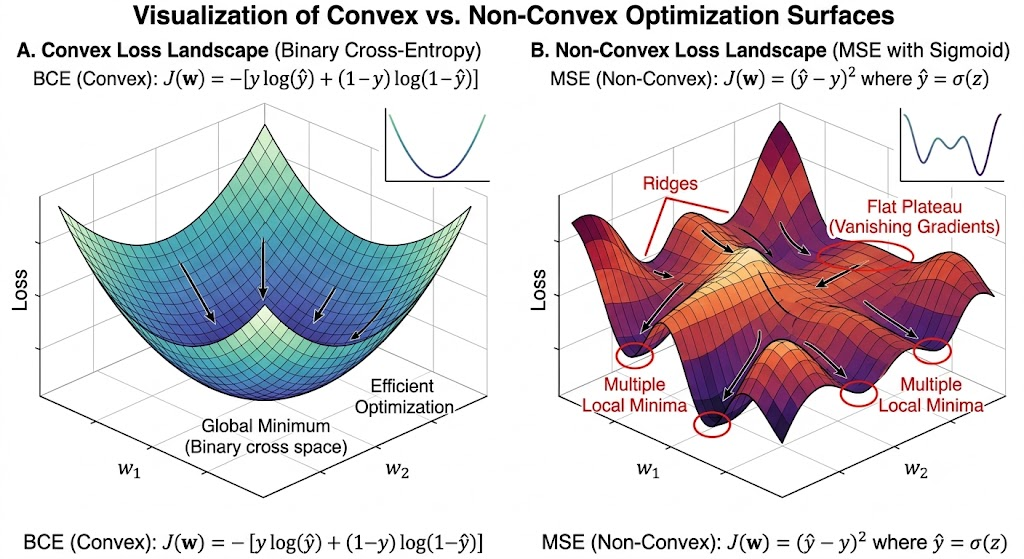

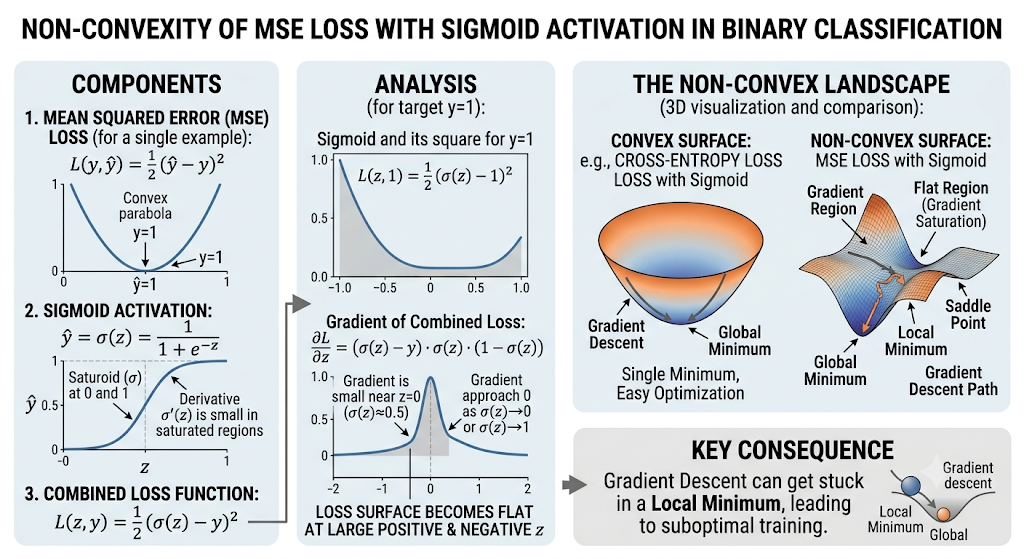

This is a fundamental concept to get right. As your favorite ML teacher, I will explain *exactly* why combining Mean Squared Error (MSE) with the Sigmoid activation function is a pairing you must avoid in classification.

The diagram above is the perfect visual for this lesson.

---

### Understanding the Landscape: Convex vs. Non-Convex

First, let's establish what a "convex" loss function means for optimization. We minimize error using **Gradient Descent**, which acts like a ball rolling downhill.

#### Diagram A: The Convex Ideal (Binary Cross-Entropy)
This surface represents the loss landscape when you use the correct pairing: **Sigmoid + Binary Cross-Entropy (Log Loss).**

*   **Shape:** It is a simple, smooth, symmetrical **bowl**.
*   **Property:** Mathematically, any line segment drawn between two points on the surface always lies *above* or *on* the surface.
*   **Result:** It contains exactly **one global minimum**. No matter where the "ball" (your model's weights, $w_1$ and $w_2$) starts, gradient descent will smoothly roll it down to the same absolute lowest point. It is highly efficient and predictable.

#### Diagram B: The Non-Convex Nightmare (MSE + Sigmoid)
This surface shows the reality of pairing **Sigmoid + MSE.**

When we try to fit a binary outcome ($y \in \{0, 1\}$) using MSE on a probability output, the non-linear "S" shape of the Sigmoid function (specifically, its asymptotes) ripples through the error calculation. The resulting mathematical function is no longer convex.

*   **Shape:** It is complex, wavy, and looks like **rugged mountain terrain**.
*   **Property:** It violates the line segment rule, dipping in some places and bulging in others.
*   **Result:** It contains **multiple local minima** (the small valleys highlighted with red circles).

### Why Non-Convexity Fails Gradient Descent

Look closely at the surface in Diagram B and the red labels.

1.  **Multiple Local Minima (The Trap):** If your gradient descent starts in the upper left of B, the gradient (the local slope) will pull the weights down into the nearest shallow valley. Your model will stop training, "thinking" it has found the minimum error. In reality, a much better solution (the lower global minimum) exists elsewhere. Your model is stuck, and its performance will be sub-optimal.

2.  **Wide Flat Plateaus (Vanishing Gradients):** The rugged terrain also generates wide, nearly flat regions (marked as a "Flat Plateau" in B). If the weights land in this area, the gradient is extremely close to zero.
    *   Think about the derivative of the Sigmoid function itself—it is practically zero when the input $z$ is very high or very low.
    *   If your model makes a very confident mistake (predicting $\hat{y}=0.999$ when the truth is $y=0$), combining MSE with Sigmoid creates a flat zone, and gradient descent will essentially stop. The weights cannot "see" which direction to move to correct the massive error.

---

### Key Summary

<Image alt="Close-up crop comparing the smooth Convex bowl (A) to the rugged, bumpy Non-Convex landscape (B)." caption="Comparison: Smooth bowl vs. Rugged mountains. Only the smooth bowl guarantees finding the optimal model parameters." src="image_0.png"/>

The choice of loss function isn't arbitrary; it alters the very physics of how your model learns.

*   A **Convex** landscape (Diagram A) offers a smooth, reliable path to the optimal answer.
*   A **Non-Convex** landscape (Diagram B) is unpredictable, likely to trap your model in a local minimum, or leave it stranded on a flat plateau, preventing convergence. This is why for binary classification, Binary Cross-Entropy is the standard, not MSE.